# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [ ]:
# TODO: the numbers
import pandas as pd
import matplotlib.pyplot as plt

txns = pd.read_csv('transactions_clean.csv', parse_dates=['timestamp'])
print(f'rows loaded: {len(txns):,}')

CATEGORY_MAP = {
    'emergency supplies': 'emergency', 'groceries': 'grocery',
    'games & entertainment': 'entertainment', 'household essentials': 'household',
    'baby products': 'baby', 'breakfast foods': 'breakfast',
    'alcoholic beverages': 'alcohol', 'health & wellness': 'health',
}
txns['category_clean'] = txns['category'].str.strip().str.lower().replace(CATEGORY_MAP)
print('category spellings:', txns['category'].nunique(), '->', txns['category_clean'].nunique())

dated = txns.dropna(subset=['timestamp']).copy()
dated['date'] = dated['timestamp'].dt.normalize()
print(f'rows with no timestamp, excluded from Q1 only: {len(txns) - len(dated):,}')

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-15')
SURGE_START    = pd.Timestamp('2024-09-21')
SURGE_END      = pd.Timestamp('2024-09-25')

daily_units = dated.groupby('date')['quantity'].sum()
baseline_days = daily_units[BASELINE_START:BASELINE_END]
surge_days    = daily_units[SURGE_START:SURGE_END]

baseline_avg = baseline_days.mean()
surge_avg    = surge_days.mean()
q1_multiple  = surge_avg / baseline_avg

print()
print(f'Baseline window: {BASELINE_START:%b %d} - {BASELINE_END:%b %d}, 2024 ({len(baseline_days)} days)')
print(f'Surge window:    {SURGE_START:%b %d} - {SURGE_END:%b %d}, 2024 ({len(surge_days)} days)')
print(f'Baseline average: {baseline_avg:,.0f} units/day')
print(f'Surge average:    {surge_avg:,.0f} units/day')
print(f'Surge multiple:   {q1_multiple:.2f}x')
print(f'Peak day: {daily_units.idxmax():%b %d} at {daily_units.max():,} units '
      f'({daily_units.max() / baseline_avg:.2f}x baseline)')

cat_daily = dated.groupby(['date', 'category_clean'])['quantity'].sum().unstack(fill_value=0)
by_cat = pd.DataFrame({
    'baseline_avg': cat_daily[BASELINE_START:BASELINE_END].mean(),
    'surge_avg':    cat_daily[SURGE_START:SURGE_END].mean(),
})
by_cat['multiple'] = by_cat['surge_avg'] / by_cat['baseline_avg']
by_cat = by_cat.sort_values('multiple', ascending=False).round(2)
print()
print(by_cat)

rows loaded: 25,402
category spellings: 37 -> 10
rows with no timestamp, excluded from Q1 only: 881

Baseline window: Sep 01 - Sep 15, 2024 (15 days)
Surge window:    Sep 21 - Sep 25, 2024 (5 days)
Baseline average: 1,103 units/day
Surge average:    3,190 units/day
Surge multiple:   2.89x
Peak day: Sep 25 at 3,958 units (3.59x baseline)

                baseline_avg  surge_avg  multiple
category_clean                                   
breakfast              73.27      464.8      6.34
emergency             354.07     1196.8      3.38
electronics            70.27      208.0      2.96
alcohol                61.53      165.6      2.69
entertainment         101.60      267.6      2.63
health                 42.33      111.0      2.62
household              85.13      202.8      2.38
grocery               171.07      344.4      2.01
baby                   85.20      147.4      1.73
snacks                 58.53       81.6      1.39


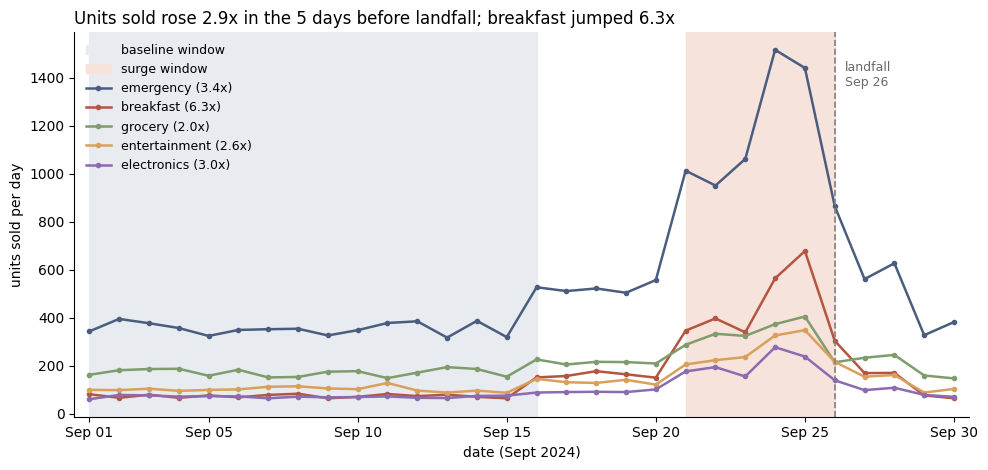

In [ ]:
# TODO: the chart
import matplotlib.dates as mdates

top5 = by_cat.sort_values('surge_avg', ascending=False).head(5).index
leader = by_cat.loc[top5, 'multiple'].idxmax()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axvspan(BASELINE_START, BASELINE_END + pd.Timedelta(days=1), color='#e8ebf0', label='baseline window')
ax.axvspan(SURGE_START, SURGE_END + pd.Timedelta(days=1), color='#f6e3dc', label='surge window')
colors = ['#4a5d7e', '#b4553f', '#7f9c6c', '#d9a05b', '#8c6bb1']
for cat, color in zip(top5, colors):
    ax.plot(cat_daily.index, cat_daily[cat], marker='o', ms=3, lw=1.8, color=color,
            label=f'{cat} ({by_cat.loc[cat, "multiple"]:.1f}x)')
ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.annotate('landfall\nSep 26', xy=(LANDFALL + pd.Timedelta(hours=8), cat_daily[top5].max().max() * 0.9),
            fontsize=9, color='dimgray')
ax.set_title(f'Units sold rose {q1_multiple:.1f}x in the 5 days before landfall; '
             f'{leader} jumped {by_cat.loc[leader, "multiple"]:.1f}x', loc='left', fontsize=12)
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 5, 10, 15, 20, 25, 30]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 12:00'))
ax.set_xlabel('date (Sept 2024)')
ax.set_ylabel('units sold per day')
ax.legend(frameon=False, fontsize=9, loc='upper left')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** In the 5 days before the hurricane's landfall on September 26th, September 21st-25th, Florida stores sold an average of 3,190 units a day, which is 2.9x the normal baseline of 1,103 units a day during September 1st–15th, with breakfast items having the largest jump at 6.3x baseline.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Distinct SKUs at start:          45
Distinct product-name spellings: 63
Canonical products after:        20

                        skus  transactions  units
product                                          
Pop-Tarts Strawberry       4          2053   5198
Bottled Water 24-Pack      3          1486   5227
AA Batteries 4-Pack        3          1453   4298
Monopoly Board Game        3          1333   2017
LED Flashlight             2          1453   2910
Canned Soup                2          1045   2637
Emergency Candles          2          1303   2618
Light Beer 24-Pack         2          1259   2581
Playing Cards              2          1194   2381
White Bread                2          1161   2288
Heavy Duty Tarp            2          1457   2193
Portable Phone Charger     2          1306   1958
Chips Variety Pack         2           972   1952
First Aid Kit              2          1221   1836
Toilet Paper 12-Roll       2          1176   1795
Paper Towels 6-Roll        2          116

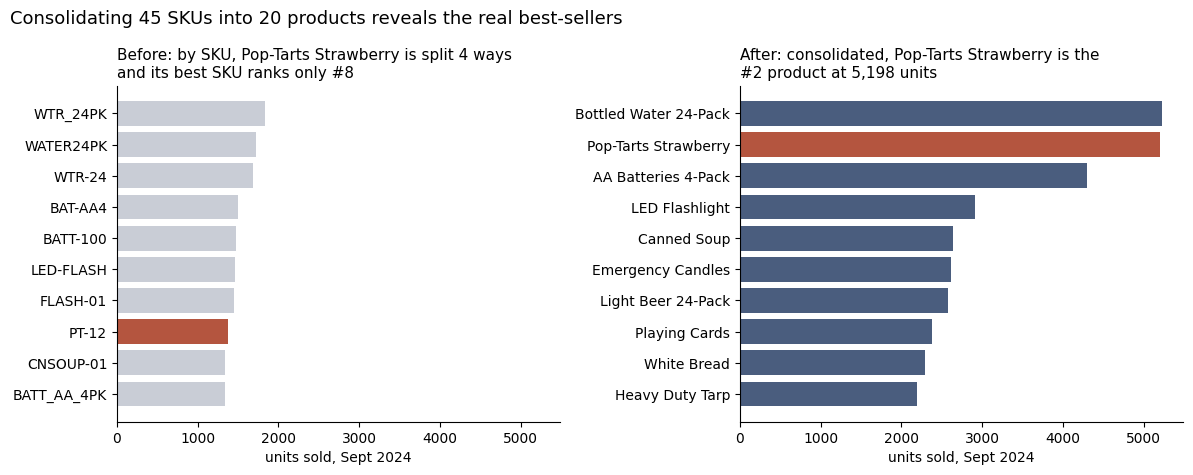

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

txns = pd.read_csv('transactions_clean.csv', parse_dates=['timestamp'])

SKU_TO_PRODUCT = {
    'PT-12': 'Pop-Tarts Strawberry', 'SKU#459812': 'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry', 'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    'WTR-24': 'Bottled Water 24-Pack', 'WATER24PK': 'Bottled Water 24-Pack', 'WTR_24PK': 'Bottled Water 24-Pack',
    'BATT-100': 'AA Batteries 4-Pack', 'BAT-AA4': 'AA Batteries 4-Pack', 'BATT_AA_4PK': 'AA Batteries 4-Pack',
    'BG-MONO': 'Monopoly Board Game', 'MONOPOLY-01': 'Monopoly Board Game', 'GAME-MONO': 'Monopoly Board Game',
    'FLASH-01': 'LED Flashlight', 'LED-FLASH': 'LED Flashlight',
    'BEER-24': 'Light Beer 24-Pack', 'LTBEER24': 'Light Beer 24-Pack',
    'CARDS-01': 'Playing Cards', 'PLAYCARD-STD': 'Playing Cards',
    'STREAM-01': 'Roku Streaming Stick', 'ROKU-STD': 'Roku Streaming Stick',
    'SOUP-CAN': 'Canned Soup', 'CNSOUP-01': 'Canned Soup',
    'BREAD-WH': 'White Bread', 'WHITEBREAD': 'White Bread',
    'PB-16': 'Peanut Butter 16oz', 'PNUTBTR-16': 'Peanut Butter 16oz',
    'CNDL-EM': 'Emergency Candles', 'CANDLE-EMRG': 'Emergency Candles',
    'FAID-01': 'First Aid Kit', 'FIRSTAID-KIT': 'First Aid Kit',
    'CHRG-PORT': 'Portable Phone Charger', 'PORTCHARGER': 'Portable Phone Charger',
    'CHIPS-VP': 'Chips Variety Pack', 'CHIPVARIETY': 'Chips Variety Pack',
    'PTOWEL-6': 'Paper Towels 6-Roll', 'PAPERTOWEL6': 'Paper Towels 6-Roll',
    'TP-12': 'Toilet Paper 12-Roll', 'TOILETPAPER12': 'Toilet Paper 12-Roll',
    'DIAP-S3': 'Diapers Size 3', 'DIAPERS-3': 'Diapers Size 3',
    'BFORM-01': 'Baby Formula', 'BABYFORMULA': 'Baby Formula',
    'TARP-HD': 'Heavy Duty Tarp', 'HDTARP-01': 'Heavy Duty Tarp',
}

unmapped = set(txns['sku']) - set(SKU_TO_PRODUCT)
assert not unmapped, f'SKUs with no mapping: {unmapped}'

txns['product'] = txns['sku'].map(SKU_TO_PRODUCT)

n_skus = txns['sku'].nunique()
n_names = txns['product_name'].nunique()
n_products = txns['product'].nunique()
print(f'Distinct SKUs at start:          {n_skus}')
print(f'Distinct product-name spellings: {n_names}')
print(f'Canonical products after:        {n_products}')

families = (txns.groupby('product')
                .agg(skus=('sku', 'nunique'), transactions=('sku', 'size'), units=('quantity', 'sum'))
                .sort_values(['skus', 'units'], ascending=False))
print()
print(families)

largest = families.index[0]
print()
print(f'Largest consolidated family: {largest} ({families.loc[largest, "skus"]} SKUs)')
print(txns[txns['product'] == largest].groupby('sku')['quantity'].agg(['size', 'sum'])
          .rename(columns={'size': 'transactions', 'sum': 'units'}))

units_by_sku = txns.groupby('sku')['quantity'].sum().sort_values(ascending=False)
units_by_product = txns.groupby('product')['quantity'].sum().sort_values(ascending=False)

assert units_by_sku.sum() == units_by_product.sum() == txns['quantity'].sum(), 'unit totals changed'
assert len(txns) == families['transactions'].sum(), 'row count changed'
print()
print(f'Assertion passed: {units_by_sku.sum():,} units before = {units_by_product.sum():,} units after')

rank_before = units_by_sku.rank(ascending=False, method='min')
rank_after = units_by_product.rank(ascending=False, method='min')
best_sku = units_by_sku[[s for s, p in SKU_TO_PRODUCT.items() if p == largest]].idxmax()
print()
print(f'{largest}: best single SKU {best_sku} ranks #{int(rank_before[best_sku])} of {n_skus} '
      f'with {units_by_sku[best_sku]:,} units')
print(f'{largest}: consolidated product ranks #{int(rank_after[largest])} of {n_products} '
      f'with {units_by_product[largest]:,} units '
      f'({units_by_product[largest] / units_by_sku[best_sku]:.1f}x its best single SKU)')

top_n = 10
before = units_by_sku.head(top_n)[::-1]
after = units_by_product.head(top_n)[::-1]
largest_skus = {s for s, p in SKU_TO_PRODUCT.items() if p == largest}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].barh(before.index, before.values,
             color=['#b4553f' if s in largest_skus else '#c9cdd6' for s in before.index])
axes[0].set_title(f'Before: by SKU, {largest} is split {families.loc[largest, "skus"]} ways\nand its best SKU ranks only #{int(rank_before[best_sku])}',
                  loc='left', fontsize=11)
axes[1].barh(after.index, after.values,
             color=['#b4553f' if p == largest else '#4a5d7e' for p in after.index])
axes[1].set_title(f'After: consolidated, {largest} is the\n#{int(rank_after[largest])} product at {units_by_product[largest]:,} units',
                  loc='left', fontsize=11)
for ax in axes:
    ax.set_xlabel('units sold, Sept 2024')
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
axes[1].set_xlim(0, units_by_product.max() * 1.05)
axes[0].set_xlim(axes[1].get_xlim())
fig.suptitle(f'Consolidating {n_skus} SKUs into {n_products} products reveals the real best-sellers',
             x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.show()

**Q2 answer:** We consolidated 45 SKUs into 20 products, and total units stayed the same. Strawberry Pop-Tarts changed the most. Split across 4 SKUs, its best one ranked only #8, but combined it’s the #2 product at 5,198 units, just behind bottled water.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

weather source: open-meteo
weather rows returned: 30
weather timezone: America/New_York (requested), same local time as the Florida sales timestamps

rows before join: 30 sales days | rows after join: 30 | all matched: True
units before: 47,897 | units after: 47,897

correlation over 30 days (Sep 1-30, 2024):
  units vs max wind, same day:     r = 0.40
  units vs precipitation, same day: r = -0.26

lag: units today vs max wind k days later
  k = 0: r = 0.40  (n = 30 days)
  k = 1: r = 0.71  (n = 29 days)
  k = 2: r = 0.82  (n = 28 days)
  k = 3: r = 0.68  (n = 27 days)
  k = 4: r = 0.47  (n = 26 days)
strongest at 2 day(s) ahead of the wind: r = 0.82


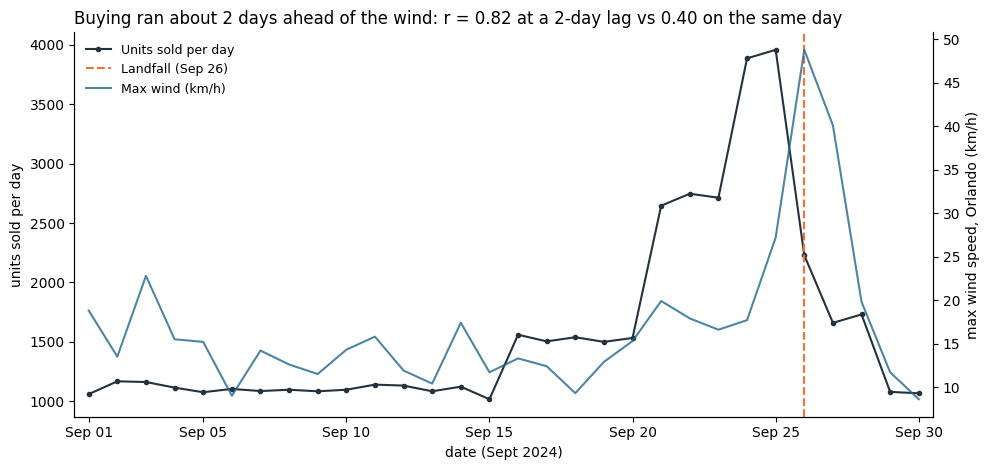

In [ ]:
# TODO
import pandas as pd
import numpy as np
import requests
import time
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

txns = pd.read_csv('transactions_clean.csv', parse_dates=['timestamp'])
LANDFALL = pd.Timestamp('2024-09-26')

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

try:
    weather = daily_weather('2024-09-01', '2024-09-30')
except requests.RequestException as err:
    print('API call failed:', err)
    weather = FALLBACK

print('weather source:', weather['source'].iloc[0])
print('weather rows returned:', len(weather))
print('weather timezone: America/New_York (requested), same local time as the Florida sales timestamps')

dated = txns.dropna(subset=['timestamp']).copy()
dated['date'] = dated['timestamp'].dt.normalize()
sales = (dated.groupby('date')
              .agg(orders=('transaction_id', 'size'), units=('quantity', 'sum'))
              .reset_index())

merged = sales.merge(weather, on='date', how='left', indicator=True)

assert len(merged) == len(sales), 'the join changed the row count'
assert (merged['_merge'] == 'both').all(), 'some sales days have no weather'
assert merged['units'].sum() == sales['units'].sum(), 'the units total changed'
print()
print(f'rows before join: {len(sales)} sales days | rows after join: {len(merged)} | all matched: True')
print(f'units before: {sales["units"].sum():,} | units after: {merged["units"].sum():,}')

q3_days = len(merged)
r_same_day = merged['units'].corr(merged['windspeed_10m_max'])
r_rain = merged['units'].corr(merged['precipitation_sum'])
print()
print(f'correlation over {q3_days} days (Sep 1-30, 2024):')
print(f'  units vs max wind, same day:     r = {r_same_day:.2f}')
print(f'  units vs precipitation, same day: r = {r_rain:.2f}')

print()
print('lag: units today vs max wind k days later')
lags = {}
for k in range(0, 5):
    pair = pd.DataFrame({'units': merged['units'], 'wind': merged['windspeed_10m_max'].shift(-k)}).dropna()
    lags[k] = pair['units'].corr(pair['wind'])
    print(f'  k = {k}: r = {lags[k]:.2f}  (n = {len(pair)} days)')
best_lag = max(lags, key=lags.get)
print(f'strongest at {best_lag} day(s) ahead of the wind: r = {lags[best_lag]:.2f}')

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(merged['date'], merged['units'], marker='o', ms=3, color='#24323E', label='Units sold per day')
ax.axvline(LANDFALL, color='#F67132', ls='--', label='Landfall (Sep 26)')
ax.set_ylabel('units sold per day')
ax.set_xlabel('date (Sept 2024)')
ax2 = ax.twinx()
ax2.plot(merged['date'], merged['windspeed_10m_max'], color='#21688D', alpha=0.8, label='Max wind (km/h)')
ax2.set_ylabel('max wind speed, Orlando (km/h)')
ax.set_title(f'Buying ran about {best_lag} days ahead of the wind: '
             f'r = {lags[best_lag]:.2f} at a {best_lag}-day lag vs {r_same_day:.2f} on the same day',
             loc='left', fontsize=12)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=False, fontsize=9)
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 5, 10, 15, 20, 25, 30]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2024-08-31 12:00'), pd.Timestamp('2024-09-30 12:00'))
for a in (ax, ax2):
    a.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

**Q3 answer, with its caveat:** Live weather joined to all 30 sales days with no rows lost. Buying ran about two days ahead of the wind, r = 0.40 on the same day, but 0.82 when compared with the wind two days later. The caveat is that this is only 28 days and one storm, with Orlando’s weather used for all 12 stores.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** This is almost done, Karen has done store analysis and she's moving it to the team notebook and adding the chart this weekend.

**Q5 (signal or artifact):** Hasn't gotten started yet, Karen will be writing the SQL queries and cross check them with Zach as the reviewer as well.

### Self-check

In [ ]:
progress = {
    'q1_multiple': round(q1_multiple, 2),            # TODO: a number
    'q1_baseline_window': 'Sep 1-15, 2024 (15 days) vs surge Sep 21-25, 2024 (5 days); landfall Sep 26',   # TODO: stated explicitly
    'q2_canonical_products': n_products,  # TODO: a number
    'q3_join_rows_preserved': len(merged) == len(sales), # TODO: True/False
    'q3_days_in_correlation': q3_days, # TODO: a number
    'charts_with_message_titles': 3,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 2.89
PASS - q1_baseline_window = Sep 1-15, 2024 (15 days) vs surge Sep 21-25, 2024 (5 days); landfall Sep 26
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 3
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

a: Our most surprising finding was that breakfast items, led by Strawberry Pop-Tarts, jumped the most in the five days before landfall: 6.3x their baseline, almost double the 3.4x for emergency supplies. We expected emergency supplies to lead, so we checked for cleaning bugs in three ways. All 37 raw category spellings mapped correctly to 10 categories. The 4 Pop-Tarts SKUs each sold about the same amount (1,255-1,381 units), so no single bad SKU was inflating the total. And our consolidation assertion showed the same 49,584 units before and after merging SKUs. The result also fits Walmart's well-known finding that Strawberry Pop-Tarts sell heavily before hurricanes, so we believe it reflects real buying behavior.

b: The number we trust least is the 0.82 correlation between daily units sold and wind speed two days later. It rests on just 28 days and one storm, so a few days around landfall drive most of it. It also uses Orlando's weather for all 12 stores, even though Helene came ashore in the Big Bend and hit stores at different times and strengths. Running it on the saved fallback data instead of the live API gives 0.83, which moves it slightly. So we treat 0.82 as evidence that people bought ahead of the storm, not proof that wind caused the buying or a precise measure of strength.